
[1] Loading data...
  Common start: 2000-01-03
  Training: 239 months (2000-02 -> 2019-12)
  Test:     48 months (2020-01 -> 2023-12)

[2] Calibration (training set)...
  BS mu:  [0.0527 0.0326 0.0484 0.0706 0.0805]
  BS mu:  [0.0527 0.0326 0.0484 0.0706 0.0805]
  MJD S&P 500: mu=0.0518  sigma=0.0668  lam=10.12  sJ2=0.020360
  MJD Bonds: mu=0.0326  sigma=0.0208  lam=5.00  sJ2=0.000757
    [fallback BS vol for MSCI Europe (VGK)]
  MJD MSCI Europe (VGK): mu=-0.0102  sigma=0.1682  lam=15.88  sJ2=0.026567
    [fallback BS vol for Gold]
  MJD Gold: mu=0.0836  sigma=0.1627  lam=16.79  sJ2=0.025197
  MJD NASDAQ-100: mu=0.0802  sigma=0.1430  lam=3.17  sJ2=0.046011

  a* BS  (CARA) = [0.2922 2.8052 0.2709 1.8453 0.6987]
  a* MJD (CARA) = [ 1.152   2.4208 -0.8295  1.2086  0.8839]

[3] Training CARA-EXP2 (N=20000, BATCH=32)...
  Iter  2000/20000  phi1=[0.225 0.089 0.209 0.494 0.416]  gap=3.0487
  Iter  4000/20000  phi1=[0.21  0.29  0.229 0.915 0.458]  gap=2.6939
  Iter  6000/20000  phi1=[0.222 0

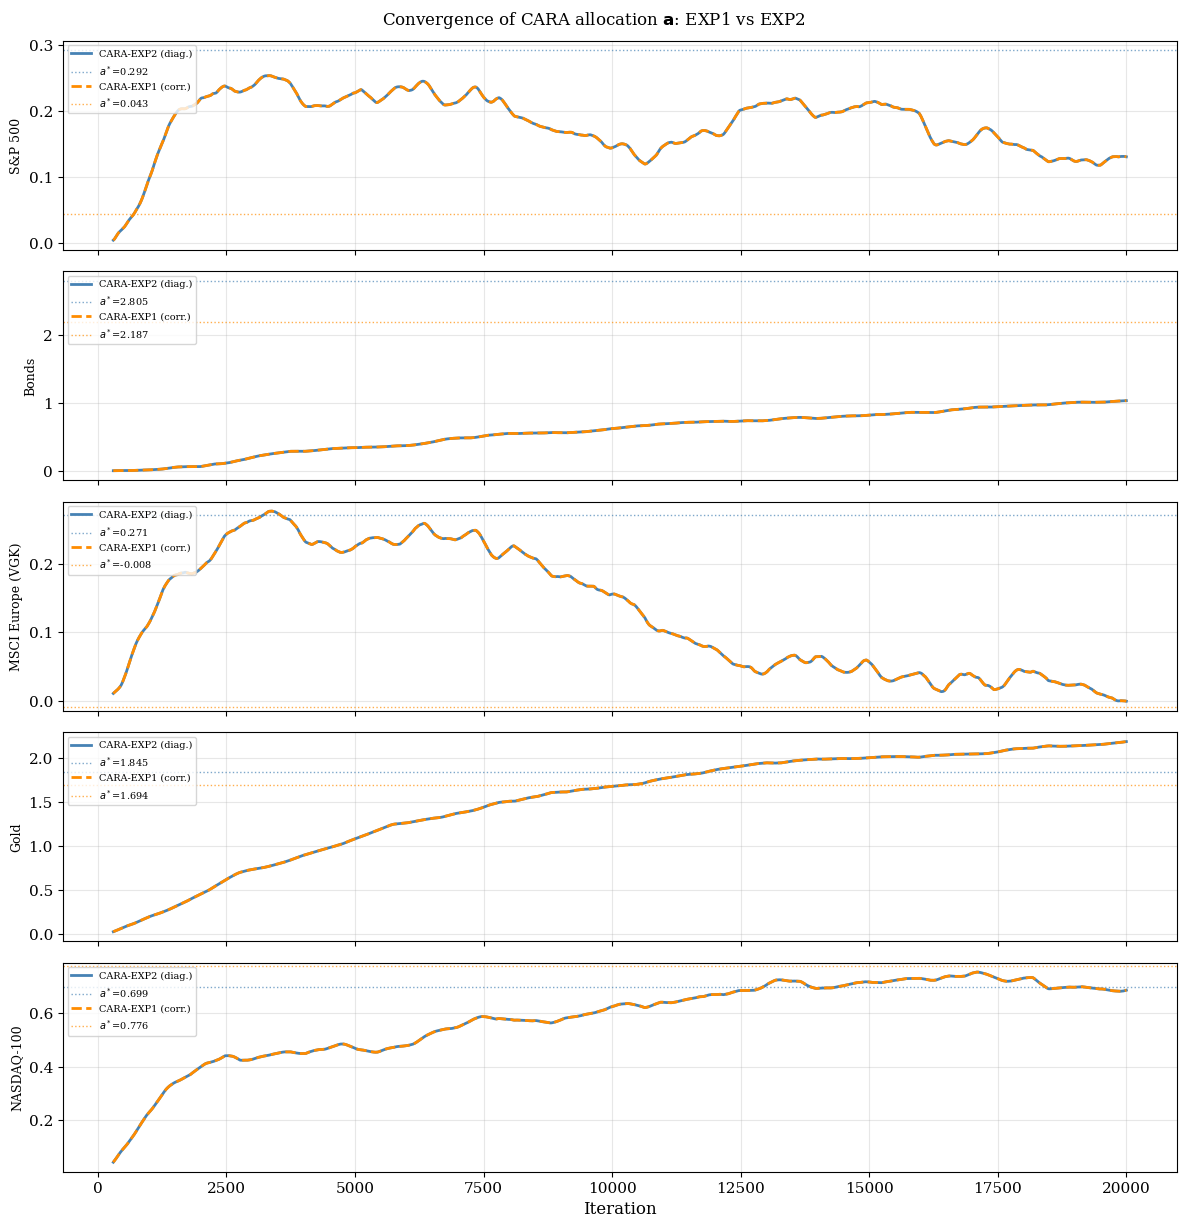

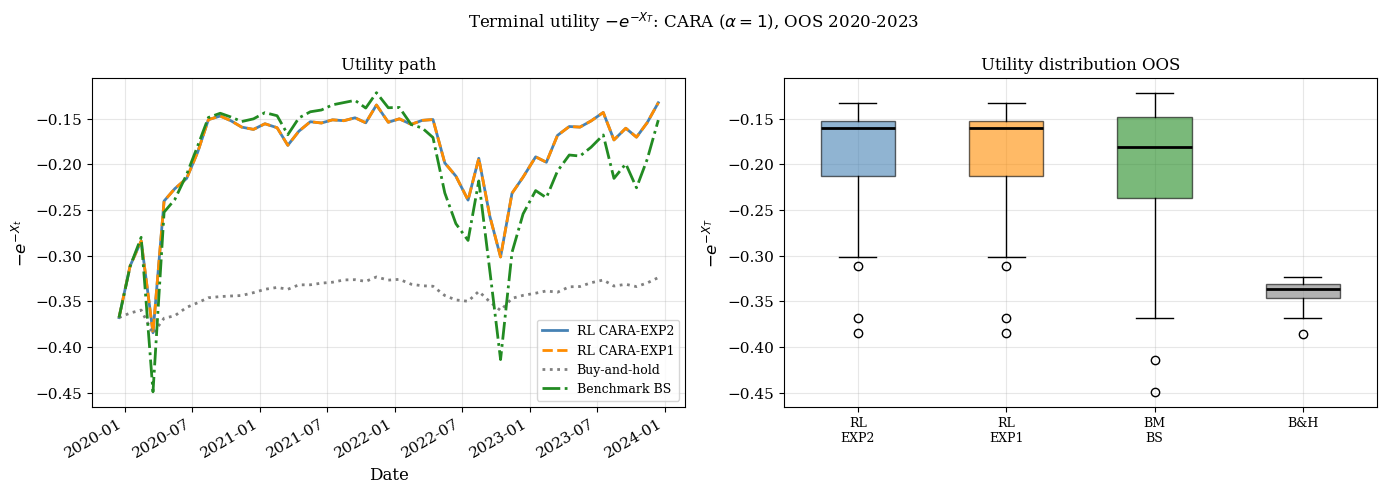


All done (CARA-EXP1 + CARA-EXP2).


In [2]:
"""
mv_multiasset_cara.py — Multi-Asset CARA Portfolio Selection
=============================================================
Variante CARA (Constant Absolute Risk Aversion) del Capitolo 7.
Usa CARAModelMulti invece di MVModelMulti.

Differenza rispetto a mv_multiasset.py (MV):
  - Value function: J(t,x) = -exp(-alpha*x * f(t))
  - Policy ottimale: COSTANTE a* = (1/alpha)*Sigma_eff^{-1}*rho
    (non dipende da x, al contrario della MV)
  - Nessun parametro omega (nessun target di ricchezza)

Con alpha=1 il benchmark coincide con quello MV.

Output:
  figure_cara_convergence.pdf/png
  figure_cara_utility.pdf/png

Utilizzo:
  python mv_multiasset_cara.py
"""

import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import matplotlib as mpl
from scipy.optimize import minimize
from scipy.stats import norm, poisson
from datetime import timedelta
import warnings
warnings.filterwarnings('ignore')

np.random.seed(42)

mpl.rcParams.update({
    'font.family':    'serif',
    'font.size':      11,
    'axes.titlesize': 12,
    'axes.labelsize': 12,
    'legend.fontsize': 10,
})

# ─────────────────────────────────────────────────────────────────────────────
# 1.  PARAMETRI GLOBALI
# ─────────────────────────────────────────────────────────────────────────────

TICKERS    = ['^GSPC', 'AGG', 'VGK', 'GLD', 'QQQ']
NAMES      = ['S&P 500', 'Bonds', 'MSCI Europe (VGK)', 'Gold', 'NASDAQ-100']
D          = len(TICKERS)

R_F         = 0.02
DT          = 1 / 12
T           = 1.0
K           = 12
THETA       = 0.1
Z           = 1.4        # kept for buy-and-hold reference only
X0          = 1.0
ALPHA_CARA  = 1.0        # CARA risk aversion parameter

N_TRAIN     = 20000
BATCH       = 32
ALPHA_PSI   = 0.001
ALPHA_OMEGA = 0.05       # unused in CARA, kept for interface compatibility
DECAY       = 0.51
GRAD_CLIP   = 5.0
ETA_TIKHONOV= 0.10       # Tikhonov level (eq. 7.15 della tesi)

ADAM_LR    = 0.001
ADAM_BETA1 = 0.9
ADAM_BETA2 = 0.999
ADAM_EPS   = 1e-8

TRAIN_END  = '2019-12-31'
TEST_END   = '2023-12-31'


# ─────────────────────────────────────────────────────────────────────────────
# 2.  DOWNLOAD E PREPROCESSING  (identical to mv_multiasset.py)
# ─────────────────────────────────────────────────────────────────────────────

def load_multiasset(tickers=TICKERS, train_end=TRAIN_END, test_end=TEST_END):
    import yfinance as yf
    import pandas as pd
    print(f"  Downloading data for {len(tickers)} assets...")
    data = yf.download(tickers, start='2000-01-01', end=test_end, progress=False)
    if isinstance(data.columns, pd.MultiIndex):
        raw = data['Close']
    else:
        raw = data
    raw = raw[list(tickers)]          # FIX: yfinance ordina le colonne alfabeticamente;
                                     # riallineale all'ordine di tickers/NAMES
    raw = raw.ffill().bfill()
    first_valid = raw.apply(lambda col: col.first_valid_index()).max()
    raw = raw.loc[first_valid:]
    print(f"  Common start: {raw.index[0].strftime('%Y-%m-%d')}")
    log_daily = np.log(raw / raw.shift(1)).dropna()
    dpm = 21
    n_months = len(log_daily) // dpm
    ret_monthly = np.zeros((n_months, len(tickers)))
    dates_monthly = []
    for i in range(n_months):
        block = log_daily.iloc[i*dpm:(i+1)*dpm]
        ret_monthly[i] = block.sum().values
        dates_monthly.append(pd.Timestamp(block.index[-1]))
    dates_monthly = np.array(dates_monthly)
    cutoff = pd.Timestamp(train_end)
    mask_train = np.array([d <= cutoff for d in dates_monthly])
    mask_test  = ~mask_train
    ret_train   = ret_monthly[mask_train]
    ret_test    = ret_monthly[mask_test]
    dates_train = dates_monthly[mask_train]
    dates_test  = dates_monthly[mask_test]
    print(f"  Training: {len(ret_train)} months "
          f"({dates_train[0].strftime('%Y-%m')} -> "
          f"{dates_train[-1].strftime('%Y-%m')})")
    print(f"  Test:     {len(ret_test)} months "
          f"({dates_test[0].strftime('%Y-%m')} -> "
          f"{dates_test[-1].strftime('%Y-%m')})")
    return ret_train, ret_test, dates_train, dates_test


# ─────────────────────────────────────────────────────────────────────────────
# 3.  CALIBRAZIONE  (identical to mv_multiasset.py)
# ─────────────────────────────────────────────────────────────────────────────

def calibrate_bs_multi(ret_monthly, r_f=R_F):
    mu    = ret_monthly.mean(axis=0)/DT + 0.5*(ret_monthly.std(axis=0)/np.sqrt(DT))**2
    Sigma = np.cov(ret_monthly.T)/DT
    rho   = mu - r_f
    print(f"  BS mu:  {np.round(mu,4)}")
    return dict(mu=mu, Sigma=Sigma, rho=rho, SigmaJ=np.zeros((D,D)))


def calibrate_mjd_multi(ret_monthly, r_f=R_F):
    bs = calibrate_bs_multi(ret_monthly, r_f)
    mu_vec = bs['mu'].copy(); sigmaJ_sq = np.zeros(D); sigma_diff = np.zeros(D)
    for i in range(D):
        ri = ret_monthly[:, i]
        def neg_ll(params):
            mu_i, sig_i, lam_i, m_i, delta_i = params
            if sig_i <= 0 or lam_i <= 0 or delta_i <= 0: return 1e10
            kappa = np.exp(m_i + 0.5*delta_i**2) - 1
            n_max = max(10, int(lam_i*DT*5+20))
            pn  = __import__('scipy.stats', fromlist=['poisson']).poisson.pmf(
                np.arange(n_max+1), lam_i*DT)
            pdf = np.zeros(len(ri))
            for n, p_n in zip(range(n_max+1), pn):
                if p_n < 1e-15: continue
                mn = (mu_i-0.5*sig_i**2-lam_i*kappa)*DT + n*m_i
                vn = sig_i**2*DT + n*delta_i**2
                pdf += p_n*norm.pdf(ri, mn, np.sqrt(vn))
            return -np.sum(np.log(np.maximum(pdf, 1e-300)))
        sig0 = np.std(ri)/np.sqrt(DT)
        try:
            res = minimize(neg_ll, [mu_vec[i],sig0,5.,-0.01,0.03],
                           method='L-BFGS-B',
                           bounds=[(None,None),(1e-4,None),(1e-4,None),(None,None),(1e-4,None)],
                           options=dict(maxiter=300, ftol=1e-8))
            mu_i, sig_i, lam_i, m_i, delta_i = res.x
        except Exception:
            mu_i, sig_i, lam_i, m_i, delta_i = mu_vec[i], sig0, 5., -0.01, 0.03
        sig_bs_i = np.std(ret_monthly[:,i])/np.sqrt(DT)
        if sig_i < 0.30*sig_bs_i:
            sig_i = sig_bs_i
            print(f"    [fallback BS vol for {NAMES[i]}]")
        sigma_diff[i] = sig_i
        sigmaJ_sq[i]  = lam_i*(np.exp(2*m_i+2*delta_i**2)-2*np.exp(m_i+0.5*delta_i**2)+1)
        mu_vec[i] = mu_i
        print(f"  MJD {NAMES[i]}: mu={mu_i:.4f}  sigma={sig_i:.4f}  "
              f"lam={lam_i:.2f}  sJ2={sigmaJ_sq[i]:.6f}")
    corr  = np.corrcoef(ret_monthly.T)
    Sigma = np.outer(sigma_diff, sigma_diff)*corr
    Sigma = 0.5*(Sigma+Sigma.T)
    ev, evec = np.linalg.eigh(Sigma)
    Sigma = evec @ np.diag(np.maximum(ev, 1e-8)) @ evec.T
    return dict(mu=mu_vec, Sigma=Sigma, rho=mu_vec-r_f,
                SigmaJ=np.diag(sigmaJ_sq), sigma_diff=sigma_diff)


def phi1_star_cara(params, alpha=ALPHA_CARA):
    """
    CARA optimal allocation: a* = (1/alpha) * (Sigma_eff + eps*I)^{-1} * rho
    With Tikhonov regularization eta=0.10 (eq. 7.15 della tesi).
    Note: with alpha=1 this coincides with the MV benchmark phi1*.
    """
    Sigma_eff = params['Sigma'] + params['SigmaJ']
    eps = ETA_TIKHONOV / D * np.trace(Sigma_eff)
    return (1./alpha) * np.linalg.solve(Sigma_eff + eps*np.eye(D), params['rho'])


# ─────────────────────────────────────────────────────────────────────────────
# 4.  SIMULATORE
# ─────────────────────────────────────────────────────────────────────────────

class RealDataSimulatorMulti:
    def __init__(self, ret_monthly):
        self.returns = ret_monthly
    def simulate_trajectory(self, n=K):
        idx = np.random.randint(0, len(self.returns), size=n)
        return self.returns[idx]


# ─────────────────────────────────────────────────────────────────────────────
# 5.  MODELLO CARA MULTI-ASSET
# ─────────────────────────────────────────────────────────────────────────────

class CARAModelMulti:
    """
    Multi-asset CARA q-learning parametric model.

    Value function ansatz (exponential form):
        J^psi(t,x) = -exp(-alpha*x * psi1*exp(-psi2*(T-t)) + psi3*(T-t))

    q-function (clipped-quadratic, mean action is CONSTANT phi1):
        q^phi(t,x,a) = -c(t)/2 * ||a - phi1||^2
                       - d*theta/2*[log(2*pi*theta) + phi2 + phi3*(T-t)]

    Key difference from MV: mean action phi1 does NOT depend on x.
    This reflects the CARA optimal allocation being wealth-independent.
    """
    def __init__(self, d=D, psi3_init=0., alpha=ALPHA_CARA):
        self.d     = d
        self.alpha = alpha
        self.psi   = np.array([1., 0., psi3_init])
        self.phi1  = np.zeros(d)
        self.phi2  = 0.
        self.phi3  = 0.

    def _logvar(self, t):
        return np.clip(self.phi2 + self.phi3*(T-t), -20, 20)

    def _c(self, t):
        return np.exp(-self._logvar(t))

    def J(self, t, x):
        psi1, psi2, psi3 = self.psi
        f_t = psi1 * np.exp(np.clip(-psi2*(T-t), -30, 30))
        return -np.exp(-self.alpha * x * f_t + psi3*(T-t))

    def grad_J(self, t, x):
        psi1, psi2, psi3 = self.psi
        e_t   = np.exp(np.clip(-psi2*(T-t), -30, 30))
        J_val = self.J(t, x)
        dh1 = -self.alpha * x * e_t
        dh2 =  self.alpha * x * psi1 * (T-t) * e_t
        dh3 =  (T-t)
        return np.array([J_val*dh1, J_val*dh2, J_val*dh3])

    def q(self, t, x, a):
        c  = self._c(t)
        lv = self._logvar(t)
        r  = a - self.phi1
        return (-c/2*np.dot(r,r)
                - self.d*THETA/2*(np.log(2*np.pi*THETA)+lv))

    def grad_q(self, t, x, a):
        c  = self._c(t)
        r  = a - self.phi1
        rr = np.dot(r, r)
        g1 = c * r
        g2 = 0.5*c*rr - self.d*THETA/2
        g3 = (T-t)*(0.5*c*rr - self.d*THETA/2)
        return g1, g2, g3

    def sample_action(self, t, x):
        std_a = max(np.sqrt(THETA*np.exp(np.clip(self._logvar(t),-20,20))), 1e-6)
        return np.random.normal(self.phi1, std_a)

    def mean_action(self, t, x):
        return self.phi1.copy()


# ─────────────────────────────────────────────────────────────────────────────
# 6.  TRAINING
# ─────────────────────────────────────────────────────────────────────────────

def offline_training_cara(sim, psi3_init, phi1_star_vec):
    model = CARAModelMulti(d=D, psi3_init=psi3_init)
    phi1_hist = np.zeros((N_TRAIN, D))
    m_phi1 = np.zeros(D); v_phi1 = np.zeros(D)
    m_phi2 = 0.; v_phi2 = 0.
    m_phi3 = 0.; v_phi3 = 0.
    adam_t = 0

    for j in range(1, N_TRAIN+1):
        lr = j**(-DECAY)
        d_psi  = np.zeros(3)
        d_phi1 = np.zeros(D); d_phi2 = 0.; d_phi3 = 0.

        for _ in range(BATCH):
            rets = sim.simulate_trajectory(K)
            xs   = np.zeros(K+1); acts = np.zeros((K,D)); xs[0] = X0
            for k in range(K):
                acts[k] = model.sample_action(k*DT, xs[k])
                r_excess = np.exp(rets[k]) - 1 - R_F*DT
                xn = xs[k] + np.dot(acts[k], r_excess)
                xs[k+1] = xn if np.isfinite(xn) else xs[k]
            for k in range(K):
                td = (model.J((k+1)*DT, xs[k+1])
                      - model.J(k*DT, xs[k])
                      - model.q(k*DT, xs[k], acts[k])*DT)
                if np.isfinite(td):
                    d_psi  += model.grad_J(k*DT, xs[k]) * td / K
                    g1, g2, g3 = model.grad_q(k*DT, xs[k], acts[k])
                    d_phi1 += g1*td/K; d_phi2 += g2*td/K; d_phi3 += g3*td/K

        # Gradient clipping
        nm_psi = np.linalg.norm(d_psi)
        if nm_psi > GRAD_CLIP*BATCH: d_psi *= GRAD_CLIP*BATCH/nm_psi
        nm_phi = np.sqrt(np.dot(d_phi1,d_phi1)+d_phi2**2+d_phi3**2)
        if nm_phi > GRAD_CLIP*BATCH:
            s = GRAD_CLIP*BATCH/nm_phi
            d_phi1 *= s; d_phi2 *= s; d_phi3 *= s

        model.psi += lr*ALPHA_PSI*d_psi/BATCH

        # Adam phi
        adam_t += 1
        g1b = d_phi1/BATCH; g2b = d_phi2/BATCH; g3b = d_phi3/BATCH
        m_phi1 = ADAM_BETA1*m_phi1 + (1-ADAM_BETA1)*g1b
        v_phi1 = ADAM_BETA2*v_phi1 + (1-ADAM_BETA2)*g1b**2
        m_phi2 = ADAM_BETA1*m_phi2 + (1-ADAM_BETA1)*g2b
        v_phi2 = ADAM_BETA2*v_phi2 + (1-ADAM_BETA2)*g2b**2
        m_phi3 = ADAM_BETA1*m_phi3 + (1-ADAM_BETA1)*g3b
        v_phi3 = ADAM_BETA2*v_phi3 + (1-ADAM_BETA2)*g3b**2
        bc1 = 1-ADAM_BETA1**adam_t; bc2 = 1-ADAM_BETA2**adam_t
        model.phi1 += ADAM_LR*(m_phi1/bc1)/(np.sqrt(v_phi1/bc2)+ADAM_EPS)
        model.phi2 += ADAM_LR*(m_phi2/bc1)/(np.sqrt(v_phi2/bc2)+ADAM_EPS)
        model.phi3 += ADAM_LR*(m_phi3/bc1)/(np.sqrt(v_phi3/bc2)+ADAM_EPS)
        model.phi2 = np.clip(model.phi2, -10, 10)
        model.phi3 = np.clip(model.phi3, -10, 10)

        phi1_hist[j-1] = model.phi1.copy()

        if j % 2000 == 0:
            gap = np.linalg.norm(phi1_star_vec - model.phi1)
            print(f"  Iter {j:5d}/{N_TRAIN}  phi1={np.round(model.phi1,3)}"
                  f"  gap={gap:.4f}")

    return model, phi1_hist


# ─────────────────────────────────────────────────────────────────────────────
# 7.  VALUTAZIONE OOS
# ─────────────────────────────────────────────────────────────────────────────

def evaluate_oos_cara(model, ret_test, phi1_bs, phi1_mjd):
    n = len(ret_test)
    W_rl  = np.zeros(n+1); W_rl[0]  = X0
    W_bh  = np.zeros(n+1); W_bh[0]  = X0
    W_bs  = np.zeros(n+1); W_bs[0]  = X0
    W_mjd = np.zeros(n+1); W_mjd[0] = X0
    a_bh  = np.ones(D)*(Z-X0)/D

    for k, r in enumerate(ret_test):
        t = (k % K)*DT; r_ex = np.exp(r)-1-R_F*DT
        a_rl  = model.mean_action(t, W_rl[k])
        W_rl[k+1]  = W_rl[k]  + np.dot(a_rl,  r_ex)
        W_bh[k+1]  = W_bh[k]  + np.dot(a_bh,  r_ex)
        W_bs[k+1]  = W_bs[k]  + np.dot(phi1_bs,  r_ex)
        W_mjd[k+1] = W_mjd[k] + np.dot(phi1_mjd, r_ex)

    return W_rl, W_bh, W_bs, W_mjd


def stats(w):
    r = np.diff(np.log(np.maximum(w, 1e-8)))
    ar = r.mean()*12; av = r.std()*np.sqrt(12)
    sh = (ar-R_F)/av if av > 0 else np.nan
    dd = np.min(w/np.maximum.accumulate(w))-1
    return w[-1], ar, av, sh, dd


# ─────────────────────────────────────────────────────────────────────────────
# 8.  EXP2 MAIN (diagonal SigmaJ)
# ─────────────────────────────────────────────────────────────────────────────

if __name__ == '__main__':
    print("\n[1] Loading data...")
    ret_train, ret_test, dates_train, dates_test = load_multiasset()

    print("\n[2] Calibration (training set)...")
    bs_params  = calibrate_bs_multi(ret_train)
    mjd_params = calibrate_mjd_multi(ret_train)

    PHI1_BS  = phi1_star_cara(bs_params)
    PHI1_MJD = phi1_star_cara(mjd_params)
    print(f"\n  a* BS  (CARA) = {np.round(PHI1_BS,  4)}")
    print(f"  a* MJD (CARA) = {np.round(PHI1_MJD, 4)}")

    psi3_init = 0.0   # CARA: time-value learned during training

    print(f"\n[3] Training CARA-EXP2 (N={N_TRAIN}, BATCH={BATCH})...")
    sim = RealDataSimulatorMulti(ret_train)
    model, phi1_hist = offline_training_cara(sim, psi3_init, PHI1_BS)

    gap_bs  = np.linalg.norm(PHI1_BS  - model.phi1)
    gap_mjd = np.linalg.norm(PHI1_MJD - model.phi1)
    print(f"\n  learned phi1  = {np.round(model.phi1, 4)}")
    print(f"  ||gap BS||    = {gap_bs:.4f}")
    print(f"  ||gap MJD||   = {gap_mjd:.4f}")

    print("\n[4] OOS evaluation (2020-2023)...")
    W_rl, W_bh, W_bs, W_mjd = evaluate_oos_cara(
        model, ret_test, PHI1_BS, PHI1_MJD)

    test_dates = np.concatenate([[dates_test[0]-timedelta(days=30)], dates_test])

    print("\n" + "="*68)
    print("  OOS STATISTICS CARA-EXP2 (2020-2023, annualised)")
    print("="*68)
    print(f"  {'Strategy':<25} {'X_T':>7} {'Ret%':>7} {'Vol%':>7} {'Sharpe':>8} {'MaxDD':>8}")
    print(f"  {'-'*60}")
    for lbl, w in [('RL CARA',      W_rl),
                   ('Buy-and-hold', W_bh),
                   ('Benchmark BS', W_bs),
                   ('Benchmark MJD',W_mjd)]:
        xt, ar, av, sh, dd = stats(w)
        print(f"  {lbl:<25} {xt:>7.4f} {ar*100:>7.2f} {av*100:>7.2f}"
              f" {sh:>8.4f} {dd:>8.2%}")
    print("="*68)
    print("\nCARA-EXP2 done.")


# ─────────────────────────────────────────────────────────────────────────────
# CARA-EXP1: Full SigmaJ via Threshold Estimator
# ─────────────────────────────────────────────────────────────────────────────

def load_daily_returns_cara(tickers=TICKERS, test_end=TEST_END,
                             train_end=TRAIN_END):
    import yfinance as yf, pandas as pd
    data = yf.download(tickers, start='2000-01-01', end=test_end, progress=False)
    raw  = data['Close'] if isinstance(data.columns, pd.MultiIndex) else data
    raw  = raw[list(tickers)]          # FIX: riallinea colonne all'ordine di tickers/NAMES
    raw  = raw.ffill().bfill()
    raw  = raw.loc[raw.apply(lambda c: c.first_valid_index()).max():]
    log_daily = np.log(raw/raw.shift(1)).dropna()
    return log_daily.loc[log_daily.index <= pd.Timestamp(train_end)].values


def threshold_estimator_cara(daily, c=10., dt=1/252):
    n, d  = daily.shape
    sig   = daily.std(axis=0)
    thr   = c*sig*np.sqrt(dt*np.log(1./dt))
    isjmp = np.abs(daily) > thr[None,:]
    print(f"  Threshold Estimator (c={c}):")
    for i in range(d):
        nj = isjmp[:,i].sum()
        print(f"    {NAMES[i]:<22}: jumps={nj} ({100*nj/n:.1f}%)")
    SJ = np.zeros((d,d))
    for i in range(d):
        for j in range(i,d):
            m = isjmp[:,i]&isjmp[:,j]
            v = np.mean(daily[:,i]*daily[:,j]*m)/dt if m.sum()>0 else 0.
            SJ[i,j] = SJ[j,i] = v
    SJ = 0.5*(SJ+SJ.T)
    ev, evec = np.linalg.eigh(SJ)
    SJ = evec @ np.diag(np.maximum(ev,1e-8)) @ evec.T
    Stot  = np.cov(daily.T)/dt
    Sdiff = Stot - SJ; Sdiff = 0.5*(Sdiff+Sdiff.T)
    ev2, evec2 = np.linalg.eigh(Sdiff)
    Sdiff = evec2 @ np.diag(np.maximum(ev2,1e-8)) @ evec2.T
    return SJ, Sdiff


if __name__ == '__main__':
    print("\n" + "="*68)
    print("  CARA-EXP1: Full SigmaJ (Threshold Estimator, c=10)")
    print("="*68)

    daily_train = load_daily_returns_cara()
    print(f"  Daily obs: {daily_train.shape[0]} x {daily_train.shape[1]}")

    SigmaJ_full, Sigma_diff = threshold_estimator_cara(daily_train)
    corr_params = dict(mu=bs_params['mu'], rho=bs_params['rho'],
                       Sigma=Sigma_diff, SigmaJ=SigmaJ_full)
    PHI1_CORR = phi1_star_cara(corr_params)
    print(f"\n  a* correlated (CARA-EXP1) = {np.round(PHI1_CORR, 3)}")

    print(f"\n  Training CARA-EXP1 (N={N_TRAIN})...")
    np.random.seed(42)
    model_corr, phi1_hist_corr = offline_training_cara(
        RealDataSimulatorMulti(ret_train), psi3_init, PHI1_CORR)

    gap_corr = np.linalg.norm(PHI1_CORR - model_corr.phi1)
    print(f"  learned phi1 = {np.round(model_corr.phi1,3)}")
    print(f"  ||gap corr|| = {gap_corr:.4f}")

    W_rl_c, W_bh_c, W_bs_c, W_corr = evaluate_oos_cara(
        model_corr, ret_test, PHI1_BS, PHI1_CORR)

    print("\n" + "="*68)
    print("  OOS STATISTICS CARA-EXP1 (2020-2023, annualised)")
    print("="*68)
    print(f"  {'Strategy':<25} {'X_T':>7} {'Ret%':>7} {'Vol%':>7} {'Sharpe':>8} {'MaxDD':>8}")
    print(f"  {'-'*60}")
    for lbl, w in [('RL correlated', W_rl_c),
                   ('Buy-and-hold',  W_bh_c),
                   ('Benchmark BS',  W_bs_c),
                   ('Benchmark corr',W_corr)]:
        xt, ar, av, sh, dd = stats(w)
        print(f"  {lbl:<25} {xt:>7.4f} {ar*100:>7.2f} {av*100:>7.2f}"
              f" {sh:>8.4f} {dd:>8.2%}")
    print("="*68)

    # ── Figura convergenza ────────────────────────────────────────────────
    fig, axes = plt.subplots(D, 1, figsize=(12, 2.5*D), sharex=True)
    w_s = 300
    for i, (ax, name) in enumerate(zip(axes, NAMES)):
        for ph, col, ls, lbl, bm in [
            (phi1_hist[:,i],      'steelblue',  '-',  'CARA-EXP2 (diag.)', PHI1_BS[i]),
            (phi1_hist_corr[:,i], 'darkorange', '--', 'CARA-EXP1 (corr.)', PHI1_CORR[i]),
        ]:
            sm = np.convolve(ph, np.ones(w_s)/w_s, mode='valid')
            ax.plot(range(w_s-1,len(ph)), sm, color=col, lw=2., ls=ls, label=lbl)
            ax.axhline(bm, color=col, lw=1., ls=':', alpha=0.7,
                       label=f'$a^*$={bm:.3f}')
        ax.set_ylabel(name, fontsize=9); ax.legend(fontsize=7, loc='upper left')
        ax.grid(True, alpha=0.3)
    axes[-1].set_xlabel('Iteration')
    fig.suptitle(r'Convergence of CARA allocation $\mathbf{a}$: EXP1 vs EXP2',
                 fontsize=12)
    plt.tight_layout()
    plt.savefig('figure_cara_convergence.pdf', dpi=150, bbox_inches='tight')
    plt.savefig('figure_cara_convergence.png', dpi=150, bbox_inches='tight')
    plt.show(); plt.close()

    # ── Figura utilità ───────────────────────────────────────────────────
    def util(w): return -np.exp(-ALPHA_CARA*w)

    test_dates_p = np.concatenate([[dates_test[0]-timedelta(days=30)], dates_test])
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    fig.suptitle(r'Terminal utility $-e^{-X_T}$: CARA ($\alpha=1$), OOS 2020-2023',
                 fontsize=12)
    ax = axes[0]
    for w, col, ls, lbl in [
        (W_rl,   'steelblue',  '-',  'RL CARA-EXP2'),
        (W_rl_c, 'darkorange', '--', 'RL CARA-EXP1'),
        (W_bh,   'gray',       ':',  'Buy-and-hold'),
        (W_bs,   'forestgreen','-.', 'Benchmark BS'),
    ]:
        ax.plot(test_dates_p, util(w), color=col, lw=2., ls=ls, label=lbl)
    ax.set_xlabel('Date'); ax.set_ylabel(r'$-e^{-X_t}$')
    ax.set_title('Utility path')
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m'))
    ax.xaxis.set_major_locator(mdates.MonthLocator(bymonth=[1,7]))
    plt.setp(ax.xaxis.get_majorticklabels(), rotation=30, ha='right')
    ax.legend(fontsize=9); ax.grid(True, alpha=0.3)

    ax = axes[1]
    bp = ax.boxplot([util(W_rl), util(W_rl_c), util(W_bs), util(W_bh)],
                    patch_artist=True, widths=0.5,
                    medianprops=dict(color='black', lw=2))
    for patch, col in zip(bp['boxes'],
                          ['steelblue','darkorange','forestgreen','gray']):
        patch.set_facecolor(col); patch.set_alpha(0.6)
    ax.set_xticks([1,2,3,4])
    ax.set_xticklabels(['RL\nEXP2','RL\nEXP1','BM\nBS','B&H'], fontsize=9)
    ax.set_ylabel(r'$-e^{-X_T}$'); ax.set_title('Utility distribution OOS')
    ax.grid(True, alpha=0.3)

    plt.tight_layout()
    plt.savefig('figure_cara_utility.pdf', dpi=150, bbox_inches='tight')
    plt.savefig('figure_cara_utility.png', dpi=150, bbox_inches='tight')
    plt.show(); plt.close()

    print("\nAll done (CARA-EXP1 + CARA-EXP2).")